# Consumer Financial Complaints: Test-Set Assessment of the Final Models
**Springboard Data Science Career Track · Capstone Three** · Author: Jacob Paul

This notebook compares the predictions of the two final models from `02_preprocessing_and_modeling.ipynb` with the actual outcomes on the **2025 test set**. It loads the saved pipelines and the saved test split. **Nothing is retrained and no modelling choice is made here**, so the test set is still used only for assessment.

| Section | Question |
|---|---|
| 1 | Do the saved pipelines reproduce the test metrics reported in notebook 02? |
| 2 | **Routing:** which products are confused with which (confusion matrices, per-class precision and recall), and can confident predictions be routed automatically? |
| 3 | **Relief:** precision–recall curve, decile gains and lift, calibration of the predicted probabilities, and a bootstrap confidence interval for the gain over the structured-only model |
| 4 | **Error analysis** with redacted example narratives |
| 5 | Add the assessment metrics to `reports/model_metrics.csv` / `.md` |

**Inputs:** `models/*.joblib` and `data/processed/split_test.parquet`, both written by notebook 02. Run time is about 5 minutes.

In [1]:
import re
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.calibration import calibration_curve
from sklearn.metrics import (average_precision_score, brier_score_loss, classification_report, confusion_matrix,
                             f1_score, precision_recall_curve)

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

RANDOM_STATE = 42
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DIR, MODEL_DIR = ROOT / "data" / "processed", ROOT / "models"
REPORT_DIR, FIG_DIR = ROOT / "reports", ROOT / "reports" / "figures"


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


def add_row_features(frame):
    """Identical to notebook 02: deterministic per-row transforms the saved pipelines expect."""
    frame["log_words"] = np.log1p(frame["word_count"]).astype("float32")
    frame["log_dollar"] = np.log1p(frame["n_dollar"].fillna(0)).astype("float32")
    frame["log_exclaim"] = np.log1p(frame["n_exclaim"].fillna(0)).astype("float32")
    frame["xxxx_share"] = frame["xxxx_share"].fillna(0).astype("float32")
    frame["upper_share"] = frame["upper_share"].fillna(0).astype("float32")
    for c in ["is_older_american", "is_servicemember"]:
        frame[c] = frame[c].astype("float32")
    return frame


def precision_at_frac(y, score, frac=0.10):
    """Same definition as notebook 02 (ties broken by a fixed random order)."""
    y = np.asarray(y)
    rng = np.random.default_rng(RANDOM_STATE)
    order = np.lexsort((rng.random(len(y)), -np.asarray(score)))
    k = max(1, int(np.ceil(frac * len(y))))
    return float(y[order[:k]].mean())


print("Project root:", ROOT.name, "(all paths below are relative to it)")

Project root: consumer-complaints-capstone (all paths below are relative to it)


## 1. Load the test set and the saved pipelines, and reproduce notebook 02's test metrics
The test set is complaints received in 2025, after removing any narrative whose exact text appeared in the training or validation period (notebook 02, section 4). The relief task uses only complaints closed with monetary relief (1) or with an explanation (0), following the proposal.

In [2]:
test = add_row_features(pd.read_parquet(PROCESSED_DIR / "split_test.parquet"))
rel = test[test["relief"].notna()].reset_index(drop=True)
y_route, y_rel = test["product_clean"].to_numpy(), rel["relief"].astype(int).to_numpy()

models = {name: joblib.load(MODEL_DIR / f"{name}.joblib") for name in
          ["routing_final", "routing_structured_reference", "relief_final", "relief_structured_reference"]}
for name, pipe in models.items():
    print(f"{name:32s} {type(pipe.named_steps['model']).__name__:22s} steps: {list(pipe.named_steps)}")

route_proba = models["routing_final"].predict_proba(test)
route_classes = models["routing_final"].classes_
route_pred = route_classes[route_proba.argmax(axis=1)]
route_pred_ref = models["routing_structured_reference"].predict(test)
s_final = models["relief_final"].predict_proba(rel)[:, 1]
s_ref = models["relief_structured_reference"].predict_proba(rel)[:, 1]
print(f"\nTest set: {len(test):,} complaints for routing, {len(rel):,} for relief "
      f"({y_rel.sum():,} monetary-relief cases, base rate {y_rel.mean():.2%})")

# Consistency check against the metrics file written by notebook 02
saved = pd.read_csv(REPORT_DIR / "model_metrics.csv")
saved_final = saved[(saved["split"] == "test") & saved["model"].str.startswith("FINAL") & ~saved["model"].str.contains("sensitivity")]
check = pd.DataFrame({
    "notebook 02 (model_metrics.csv)": [saved_final.loc[saved_final["task"] == "routing", "macro_F1"].iloc[0],
                                        saved_final.loc[saved_final["task"] == "relief", "AP"].iloc[0]],
    "recomputed here": [f1_score(y_route, route_pred, average="macro"), average_precision_score(y_rel, s_final)],
}, index=["routing macro-F1", "relief AP"])
display(check)
assert np.allclose(check.iloc[:, 0], check.iloc[:, 1], atol=1e-6), "saved pipelines do not reproduce notebook 02"
print("The saved pipelines reproduce notebook 02's test metrics exactly.")

routing_final                    LogisticRegression     steps: ['prep', 'model']
routing_structured_reference     LogisticRegression     steps: ['prep', 'model']
relief_final                     LGBMClassifier         steps: ['prep', 'select', 'model']
relief_structured_reference      LGBMClassifier         steps: ['prep', 'model']



Test set: 205,922 complaints for routing, 136,440 for relief (2,997 monetary-relief cases, base rate 2.20%)


,notebook 02 (model_metrics.csv),recomputed here
routing macro-F1,0.7021,0.7021
relief AP,0.3220,0.3220


The saved pipelines reproduce notebook 02's test metrics exactly.


## 2. Routing (product): predictions vs actual products
### 2.1 Confusion matrices and per-class precision / recall
Two views of the same matrix:
- **Row-normalised (recall):** of the complaints that truly belong to a product, where did they go?
- **Column-normalised (precision):** of the complaints sent to a product's team, how many really belong there? This is what the receiving team experiences.

predicted,Credit reporting,Debt collection,Money transfer or virtual currency,Checking or savings account,Credit card,Mortgage,Vehicle loan or lease,Student loan,"Payday, title or personal loan",Prepaid card,Debt or credit management
true product,,,,,,,,,,,
Credit reporting,142756,2455,34,128,694,147,208,301,59,2,25
Debt collection,5476,11540,21,69,230,81,138,41,96,2,11
Money transfer or virtual currency,1488,62,9560,1224,275,23,2,3,24,60,3
Checking or savings account,219,81,633,8489,737,27,29,7,20,82,2
Credit card,1245,308,146,454,5853,13,18,9,73,38,3
Mortgage,120,56,5,39,21,2533,3,1,15,2,1
Vehicle loan or lease,443,154,3,22,38,58,1590,3,59,1,0
Student loan,387,51,3,9,0,22,0,1678,28,0,0
"Payday, title or personal loan",205,242,31,64,75,80,38,10,790,1,2


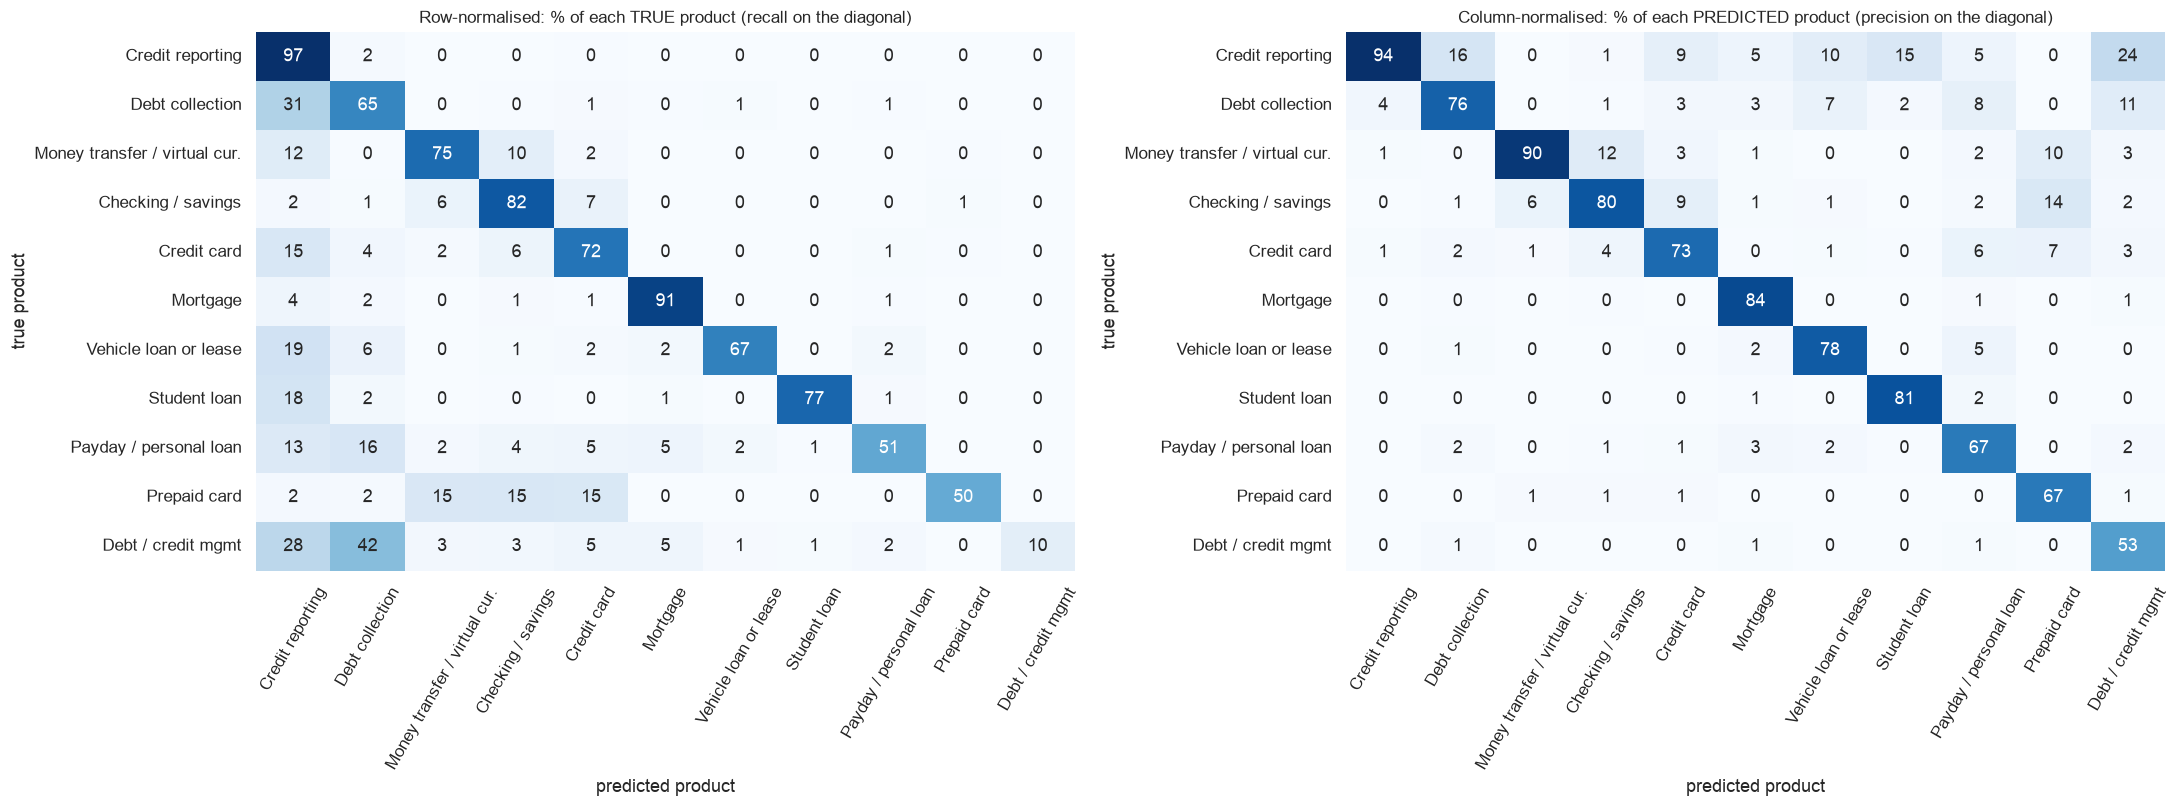

,precision,recall,f1-score,f1_structured_only,support,predicted_n
Credit reporting,0.9361,0.9724,0.9539,0.9342,146809,152502
Debt collection,0.7599,0.6518,0.7017,0.6525,17705,15186
Money transfer or virtual currency,0.9047,0.7513,0.8209,0.7395,12724,10567
Checking or savings account,0.7981,0.8221,0.8099,0.5209,10326,10636
Credit card,0.7258,0.7173,0.7215,0.5178,8160,8064
Mortgage,0.8415,0.9059,0.8725,0.7113,2796,3010
Vehicle loan or lease,0.7813,0.6706,0.7217,0.4576,2371,2035
Student loan,0.8142,0.7704,0.7917,0.7557,2178,2061
"Payday, title or personal loan",0.6706,0.5137,0.5817,0.2262,1538,1178
Prepaid card,0.6741,0.5032,0.5763,0.4483,777,580


Most frequent mis-routes:


,true product,predicted,n,share_of_true
0,Debt collection,Credit reporting,5476,0.3093
1,Credit reporting,Debt collection,2455,0.0167
2,Money transfer or virtual currency,Credit reporting,1488,0.1169
3,Credit card,Credit reporting,1245,0.1526
4,Money transfer or virtual currency,Checking or savings account,1224,0.0962
5,Checking or savings account,Credit card,737,0.0714
6,Credit reporting,Credit card,694,0.0047
7,Checking or savings account,Money transfer or virtual currency,633,0.0613


In [3]:
order = pd.Series(y_route).value_counts().index.tolist()
cm = confusion_matrix(y_route, route_pred, labels=order)
cm_df = pd.DataFrame(cm, index=pd.Index(order, name="true product"), columns=pd.Index(order, name="predicted"))
display(cm_df)

fig, axes = plt.subplots(1, 2, figsize=(20, 7.5))
short = [o.replace("Money transfer or virtual currency", "Money transfer / virtual cur.")
          .replace("Checking or savings account", "Checking / savings")
          .replace("Payday, title or personal loan", "Payday / personal loan")
          .replace("Debt or credit management", "Debt / credit mgmt") for o in order]
recall_m = cm / cm.sum(axis=1, keepdims=True)
precision_m = cm / np.maximum(cm.sum(axis=0, keepdims=True), 1)
for ax, mat, title in [(axes[0], recall_m, "Row-normalised: % of each TRUE product (recall on the diagonal)"),
                       (axes[1], precision_m, "Column-normalised: % of each PREDICTED product (precision on the diagonal)")]:
    sns.heatmap(mat * 100, annot=True, fmt=".0f", cmap="Blues", cbar=False, xticklabels=short, yticklabels=short, ax=ax)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("predicted product")
    ax.set_ylabel("true product")
    ax.tick_params(axis="x", rotation=60)
savefig("30_routing_test_confusion_recall_precision")

per_class = pd.DataFrame(classification_report(y_route, route_pred, output_dict=True, zero_division=0)).T.loc[order]
per_class["support"] = per_class["support"].astype(int)
per_class["predicted_n"] = pd.Series(route_pred).value_counts().reindex(order).fillna(0).astype(int).to_numpy()
ref_f1 = pd.DataFrame(classification_report(y_route, route_pred_ref, output_dict=True, zero_division=0)).T
per_class["f1_structured_only"] = ref_f1.loc[order, "f1-score"].to_numpy()
display(per_class[["precision", "recall", "f1-score", "f1_structured_only", "support", "predicted_n"]])

off = cm_df.stack().rename("n").reset_index()
off = off[off["true product"] != off["predicted"]]
off["share_of_true"] = off["n"] / off["true product"].map(cm_df.sum(axis=1))
print("Most frequent mis-routes:")
display(off.nlargest(8, "n").reset_index(drop=True))

### 2.2 Can confident predictions be routed automatically?
The logistic regression outputs a probability for each product. If its probabilities are reliable, a team could route high-confidence complaints automatically and send only the uncertain ones to a person. The chart compares the model's top probability with the actual accuracy in each confidence band.

,n,mean_confidence,accuracy,share_of_complaints
band,,,,
"(-0.001, 0.5]",11323,0.4175,0.5816,0.0550
"(0.5, 0.6]",9897,0.5472,0.6413,0.0481
"(0.6, 0.7]",7309,0.6492,0.6575,0.0355
"(0.7, 0.8]",7991,0.7516,0.7262,0.0388
"(0.8, 0.9]",12159,0.8555,0.8187,0.0590
"(0.9, 0.95]",13290,0.9289,0.8890,0.0645
"(0.95, 1.0]",143953,0.9890,0.9720,0.6991


,auto-routed share,accuracy of auto-routed,accuracy of the rest
confidence >= 0.8,0.8227,0.9545,0.6446
confidence >= 0.9,0.7636,0.9650,0.6881
confidence >= 0.95,0.6991,0.9720,0.7312


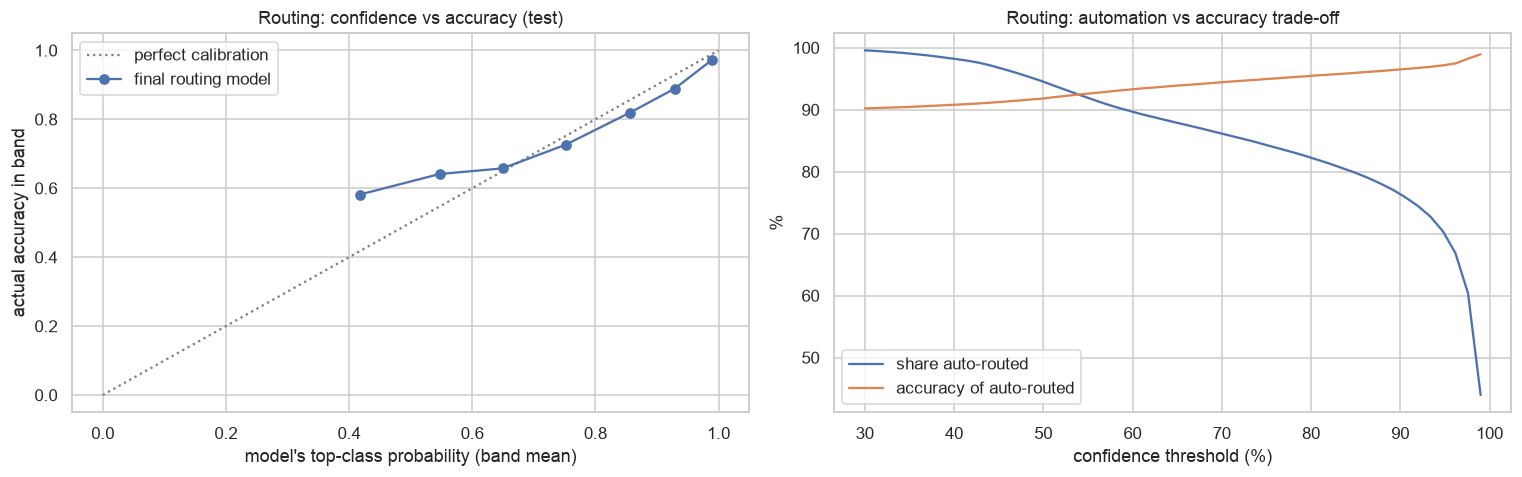

In [4]:
conf = route_proba.max(axis=1)
correct = route_pred == y_route
bands = pd.cut(conf, [0, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 1.0], include_lowest=True)
conf_tbl = pd.DataFrame({"band": bands, "conf": conf, "correct": correct}).groupby("band", observed=True).agg(
    n=("correct", "size"), mean_confidence=("conf", "mean"), accuracy=("correct", "mean"))
conf_tbl["share_of_complaints"] = conf_tbl["n"] / len(conf)
display(conf_tbl)

thresholds = [0.8, 0.9, 0.95]
auto = pd.DataFrame({"auto-routed share": [(conf >= t).mean() for t in thresholds],
                     "accuracy of auto-routed": [correct[conf >= t].mean() for t in thresholds],
                     "accuracy of the rest": [correct[conf < t].mean() for t in thresholds]},
                    index=[f"confidence >= {t}" for t in thresholds])
display(auto)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot([0, 1], [0, 1], ls=":", color="grey", label="perfect calibration")
axes[0].plot(conf_tbl["mean_confidence"], conf_tbl["accuracy"], marker="o", label="final routing model")
axes[0].set_xlabel("model's top-class probability (band mean)")
axes[0].set_ylabel("actual accuracy in band")
axes[0].set_title("Routing: confidence vs accuracy (test)")
axes[0].legend()
grid = np.linspace(0.3, 0.99, 50)
axes[1].plot(grid * 100, [(conf >= t).mean() * 100 for t in grid], label="share auto-routed")
axes[1].plot(grid * 100, [correct[conf >= t].mean() * 100 for t in grid], label="accuracy of auto-routed")
axes[1].set_xlabel("confidence threshold (%)")
axes[1].set_ylabel("%")
axes[1].set_title("Routing: automation vs accuracy trade-off")
axes[1].legend()
savefig("31_routing_confidence_and_automation")

## 3. Relief: predicted ranking vs actual monetary relief
### 3.1 Precision–recall curve and cumulative gains on test

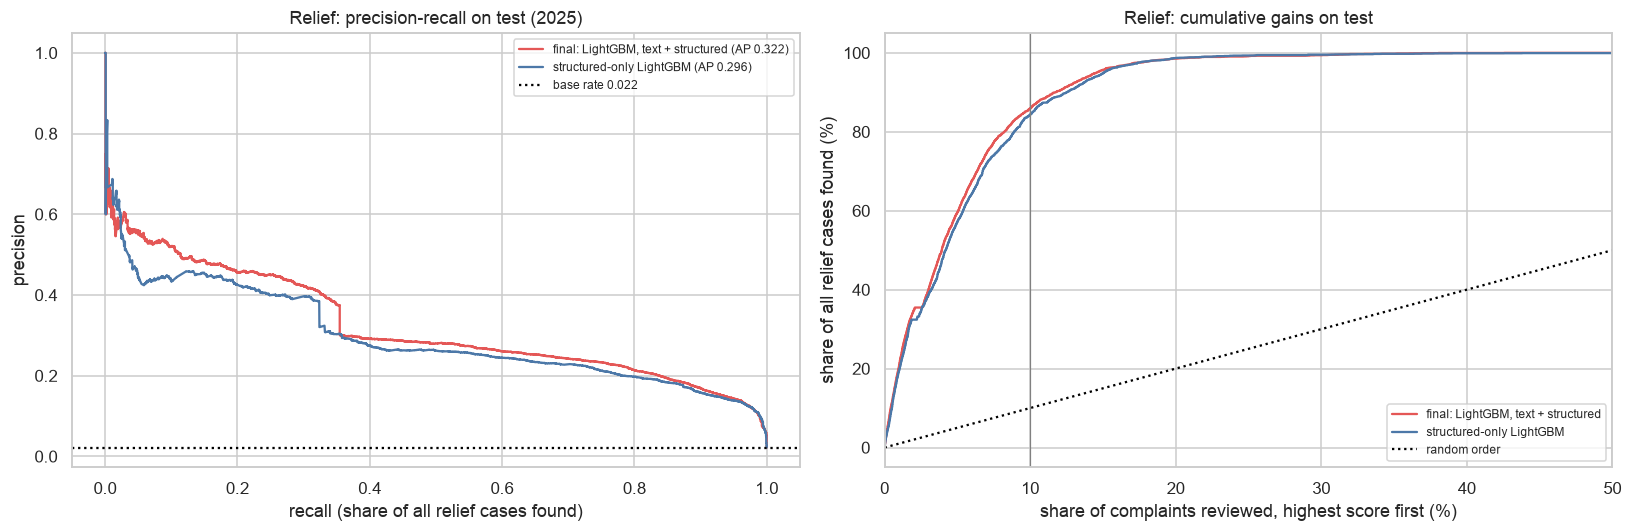

In [5]:
base = y_rel.mean()
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for s, name, color in [(s_final, "final: LightGBM, text + structured", "#E45756"),
                       (s_ref, "structured-only LightGBM", "#4C78A8")]:
    p, r, _ = precision_recall_curve(y_rel, s)
    axes[0].plot(r, p, color=color, label=f"{name} (AP {average_precision_score(y_rel, s):.3f})")
    order_idx = np.argsort(-s, kind="stable")
    cum_recall = np.cumsum(y_rel[order_idx]) / y_rel.sum()
    share = np.arange(1, len(s) + 1) / len(s)
    axes[1].plot(share * 100, cum_recall * 100, color=color, label=name)
axes[0].axhline(base, color="black", ls=":", label=f"base rate {base:.3f}")
axes[0].set_xlabel("recall (share of all relief cases found)")
axes[0].set_ylabel("precision")
axes[0].set_title("Relief: precision-recall on test (2025)")
axes[0].legend(fontsize=8)
axes[1].plot([0, 100], [0, 100], color="black", ls=":", label="random order")
axes[1].axvline(10, color="grey", lw=0.8)
axes[1].set_xlim(0, 50)
axes[1].set_xlabel("share of complaints reviewed, highest score first (%)")
axes[1].set_ylabel("share of all relief cases found (%)")
axes[1].set_title("Relief: cumulative gains on test")
axes[1].legend(fontsize=8)
savefig("32_relief_test_pr_and_gains")

### 3.2 Decile gains and lift table
Complaints are sorted by predicted relief probability and cut into ten equal groups. Decile 1 is the 10% a review team would read first. *Lift* is the decile's relief rate divided by the overall rate.

In [6]:
def decile_table(y, s):
    rng = np.random.default_rng(RANDOM_STATE)
    order_idx = np.lexsort((rng.random(len(y)), -s))
    dec = np.empty(len(y), dtype=int)
    dec[order_idx] = np.arange(len(y)) * 10 // len(y) + 1
    t = pd.DataFrame({"decile": dec, "y": y, "s": s}).groupby("decile").agg(
        complaints=("y", "size"), relief_cases=("y", "sum"), relief_rate=("y", "mean"), mean_predicted=("s", "mean"))
    t["lift"] = t["relief_rate"] / y.mean()
    t["cumulative_recall"] = t["relief_cases"].cumsum() / y.sum()
    return t


gains_final = decile_table(y_rel, s_final)
gains_ref = decile_table(y_rel, s_ref)
display(Markdown("**Final model (LightGBM, text + structured)**"))
display(gains_final)
display(Markdown("**Structured-only reference**"))
display(gains_ref[["relief_rate", "lift", "cumulative_recall"]])
print(f"Top decile: lift {gains_final.loc[1, 'lift']:.2f} (final) vs {gains_ref.loc[1, 'lift']:.2f} (structured-only); "
      f"it contains {gains_final.loc[1, 'cumulative_recall']:.1%} vs {gains_ref.loc[1, 'cumulative_recall']:.1%} of all relief cases. "
      f"Top-decile precision cannot exceed {min(1, y_rel.sum() / gains_final.loc[1, 'complaints']):.3f} here, "
      f"because the decile ({gains_final.loc[1, 'complaints']:,}) is larger than the number of relief cases ({y_rel.sum():,}).")

**Final model (LightGBM, text + structured)**

,complaints,relief_cases,relief_rate,mean_predicted,lift,cumulative_recall
decile,,,,,,
1,13644,2574,0.1887,0.2406,8.5886,0.8589
2,13644,379,0.0278,0.0352,1.2646,0.9853
3,13644,26,0.0019,0.0084,0.0868,0.9940
4,13644,17,0.0012,0.0033,0.0567,0.9997
5,13644,1,0.0001,0.0011,0.0033,1.0000
6,13644,0,0.0000,0.0007,0.0000,1.0000
7,13644,0,0.0000,0.0005,0.0000,1.0000
8,13644,0,0.0000,0.0004,0.0000,1.0000
9,13644,0,0.0000,0.0003,0.0000,1.0000


**Structured-only reference**

,relief_rate,lift,cumulative_recall
decile,,,
1,0.1852,8.4318,0.8432
2,0.0316,1.4381,0.9870
3,0.0018,0.0834,0.9953
4,0.0008,0.0367,0.9990
5,0.0001,0.0033,0.9993
6,0.0000,0.0000,0.9993
7,0.0001,0.0033,0.9997
8,0.0000,0.0000,0.9997
9,0.0001,0.0033,1.0000


Top decile: lift 8.59 (final) vs 8.43 (structured-only); it contains 85.9% vs 84.3% of all relief cases. Top-decile precision cannot exceed 0.220 here, because the decile (13,644) is larger than the number of relief cases (2,997).


### 3.3 Calibration: are the predicted probabilities trustworthy?
AP and lift only judge the *ranking*. A review team may also want to read a score as "a 30% chance of relief". The reliability curve compares the mean predicted probability with the observed relief rate in 10 equal-size bins. The **Brier score** (mean squared error of the probability) is compared with a constant forecast of the test base rate. The model was trained on 2015 – mid-2024, when relief was more common (4.6% in train vs 2.2% in test), so some **over-prediction is expected from the time drift alone**.

,mean predicted,actual rate,Brier score,ECE (10 quantile bins),Brier skill vs constant
"final: LightGBM, text + structured",0.0291,0.0220,0.0176,0.0071,0.1793
structured-only LightGBM,0.1514,0.0220,0.0818,0.1294,-2.8088
constant base-rate forecast,0.0220,0.0220,0.0215,0.0000,0.0000


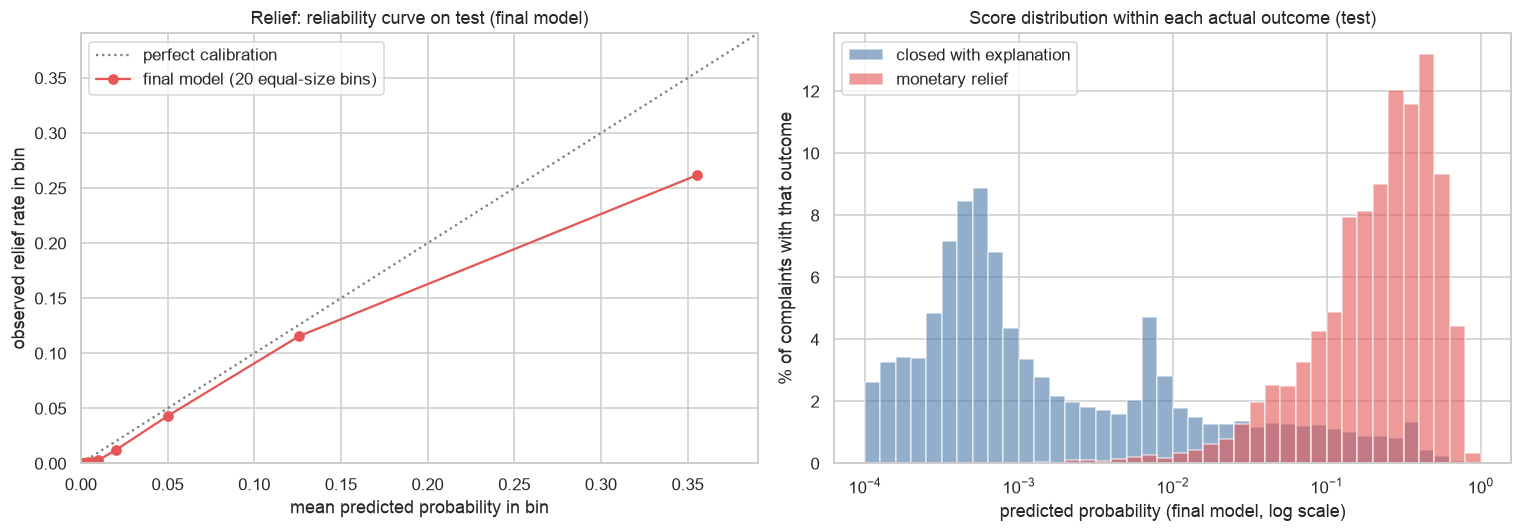

In [7]:
def ece(y, s, bins=10):
    """Expected calibration error with equal-size (quantile) bins."""
    q = pd.qcut(s, bins, labels=False, duplicates="drop")
    g = pd.DataFrame({"y": y, "s": s, "q": q}).groupby("q").agg(y=("y", "mean"), s=("s", "mean"), n=("y", "size"))
    return float((g["n"] * (g["y"] - g["s"]).abs()).sum() / g["n"].sum())


calib = pd.DataFrame({
    "mean predicted": [s_final.mean(), s_ref.mean(), base],
    "actual rate": [base, base, base],
    "Brier score": [brier_score_loss(y_rel, s_final), brier_score_loss(y_rel, s_ref), brier_score_loss(y_rel, np.full(len(y_rel), base))],
    "ECE (10 quantile bins)": [ece(y_rel, s_final), ece(y_rel, s_ref), 0.0],
}, index=["final: LightGBM, text + structured", "structured-only LightGBM", "constant base-rate forecast"])
calib["Brier skill vs constant"] = 1 - calib["Brier score"] / calib.loc["constant base-rate forecast", "Brier score"]
display(calib)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# Reliability: 20 equal-size bins of the final model's score; most bins sit near zero, the informative ones are at the top
frac_pos, mean_pred = calibration_curve(y_rel, s_final, n_bins=20, strategy="quantile")
lim = max(mean_pred.max(), frac_pos.max()) * 1.1
axes[0].plot([0, lim], [0, lim], ls=":", color="grey", label="perfect calibration")
axes[0].plot(mean_pred, frac_pos, marker="o", color="#E45756", label="final model (20 equal-size bins)")
axes[0].set_xlim(0, lim)
axes[0].set_ylim(0, lim)
axes[0].set_xlabel("mean predicted probability in bin")
axes[0].set_ylabel("observed relief rate in bin")
axes[0].set_title("Relief: reliability curve on test (final model)")
axes[0].legend(loc="upper left")
bins = np.logspace(-4, 0, 41)
for outcome, color, label in [(0, "#4C78A8", "closed with explanation"), (1, "#E45756", "monetary relief")]:
    vals = s_final[y_rel == outcome]
    axes[1].hist(vals, bins=bins, weights=np.full(len(vals), 100 / len(vals)), alpha=0.6, color=color, label=label)
axes[1].set_xscale("log")
axes[1].set_xlabel("predicted probability (final model, log scale)")
axes[1].set_ylabel("% of complaints with that outcome")
axes[1].set_title("Score distribution within each actual outcome (test)")
axes[1].legend()
savefig("33_relief_calibration")

### 3.4 Is the gain over the structured-only model real? Bootstrap confidence interval
Notebook 02 found that the narrative raises test AP from 0.296 to 0.322. To check that this is not luck in the particular test sample, the test rows are resampled with replacement 1,000 times. On each resample both models are scored, and the difference is recorded. The 2.5th and 97.5th percentiles give a 95% confidence interval.

,observed difference,95% CI low,95% CI high,share of resamples > 0
AP: final - structured-only,0.0259,0.0131,0.0380,1.0000
precision@10%: final - structured-only,0.0034,0.0012,0.0059,0.9960


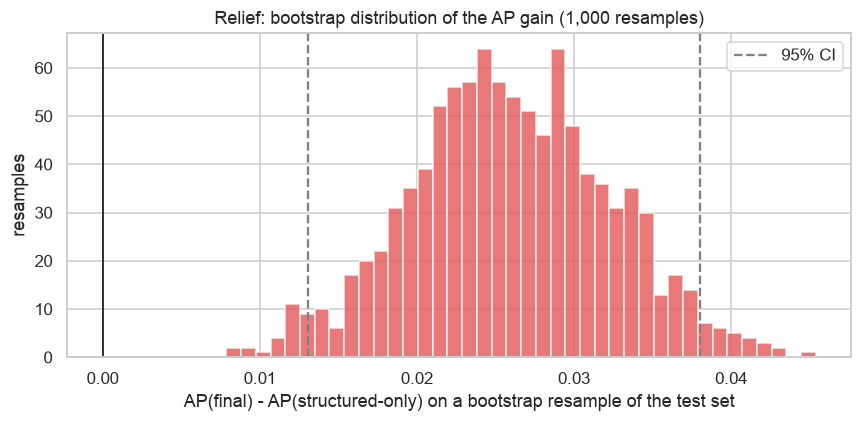

In [8]:
N_BOOT = 1000
rng = np.random.default_rng(RANDOM_STATE)
n = len(y_rel)
diff_ap, diff_p10 = np.empty(N_BOOT), np.empty(N_BOOT)
for b in range(N_BOOT):
    idx = rng.integers(0, n, n)
    yb = y_rel[idx]
    diff_ap[b] = average_precision_score(yb, s_final[idx]) - average_precision_score(yb, s_ref[idx])
    diff_p10[b] = precision_at_frac(yb, s_final[idx]) - precision_at_frac(yb, s_ref[idx])

boot = pd.DataFrame({
    "observed difference": [average_precision_score(y_rel, s_final) - average_precision_score(y_rel, s_ref),
                            precision_at_frac(y_rel, s_final) - precision_at_frac(y_rel, s_ref)],
    "95% CI low": [np.percentile(diff_ap, 2.5), np.percentile(diff_p10, 2.5)],
    "95% CI high": [np.percentile(diff_ap, 97.5), np.percentile(diff_p10, 97.5)],
    "share of resamples > 0": [(diff_ap > 0).mean(), (diff_p10 > 0).mean()],
}, index=["AP: final - structured-only", "precision@10%: final - structured-only"])
display(boot)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(diff_ap, bins=40, color="#E45756", alpha=0.8)
ax.axvline(0, color="black", lw=1)
ax.axvline(boot.iloc[0, 1], color="grey", ls="--", label="95% CI")
ax.axvline(boot.iloc[0, 2], color="grey", ls="--")
ax.set_xlabel("AP(final) - AP(structured-only) on a bootstrap resample of the test set")
ax.set_ylabel("resamples")
ax.set_title(f"Relief: bootstrap distribution of the AP gain ({N_BOOT:,} resamples)")
ax.legend()
savefig("34_relief_bootstrap_ap_gain")

## 4. Error analysis with redacted examples
The CFPB already replaces names and other personal details with `XXXX` before publishing a narrative. As an extra safeguard, the examples below also mask any remaining email addresses, web links, phone numbers, dates and long digit strings (account or reference numbers), and are cut to 300 characters. Company names are kept: the company is a public field of every complaint. Dollar amounts in the CFPB's `{$…}` format are kept, because they are part of the signal.

In [9]:
REDACT = [
    (re.compile(r"[\w.+-]+@[\w-]+\.[\w.-]+"), "[email]"),
    (re.compile(r"(https?://|www\.)\S+", re.I), "[link]"),
    (re.compile(r"\(?\b\d{3}\)?[-.\s]\d{3}[-.\s]\d{4}\b"), "[phone]"),
    (re.compile(r"\b\d{1,2}/\d{1,2}/\d{2,4}\b"), "[date]"),
    (re.compile(r"(?<![\$\d.,])\b\d{4,}\b"), "[number]"),
    (re.compile(r"\s+"), " "),
]


def redact(text, n=300):
    for pattern, repl in REDACT:
        text = pattern.sub(repl, text)
    text = text.strip()
    return text[:n] + ("…" if len(text) > n else "")


def show_examples(frame, title, cols):
    display(Markdown(f"**{title}**"))
    for _, r in frame.iterrows():
        meta = " | ".join(f"{c}: {r[c]:.3f}" if isinstance(r[c], float) else f"{c}: {r[c]}" for c in cols)
        print(f"- {meta}\n  \"{redact(r['narrative'])}\"\n")


# Routing: the most confident wrong predictions within the most frequent mis-route
test_view = test.assign(pred=route_pred, confidence=conf)
top_mis = off.nlargest(1, "n").iloc[0]
wrong = test_view[(test_view["product_clean"] == top_mis["true product"]) & (test_view["pred"] == top_mis["predicted"])]
show_examples(wrong.nlargest(3, "confidence"),
              f"Routing: {top_mis['true product']} complaints confidently routed to {top_mis['predicted']}",
              ["product_clean", "pred", "confidence", "issue"])

# Relief: missed cases (relief, lowest scores) and false alarms (no relief, highest scores)
rel_view = rel.assign(score=s_final, y=y_rel)
show_examples(rel_view[rel_view["y"] == 1].nsmallest(3, "score"), "Relief: missed relief cases (lowest scores)",
              ["product_clean", "company", "score"])
show_examples(rel_view[rel_view["y"] == 0].nlargest(3, "score"), "Relief: false alarms (highest scores, closed with explanation)",
              ["product_clean", "company", "score"])

# Who are the false alarms in the review queue? (top decile, no relief)
cut = np.quantile(s_final, 0.90)
top = rel_view[rel_view["score"] >= cut]
fa = top[top["y"] == 0]
fa_tbl = pd.DataFrame({"in top decile": top["product_clean"].value_counts(),
                       "false alarms": fa["product_clean"].value_counts()}).fillna(0).astype(int)
fa_tbl["precision in top decile"] = 1 - fa_tbl["false alarms"] / fa_tbl["in top decile"]
display(fa_tbl.sort_values("in top decile", ascending=False).head(8))

**Routing: Debt collection complaints confidently routed to Credit reporting**

- product_clean: Debt collection | pred: Credit reporting | confidence: 1.000 | issue: Attempts to collect debt not owed
  "I reached out to LexusNexus and asked for a verification letter, validation letter, A wet signature contract agreement letter, and a letter from the bankruptcy court regarding the items that is on my credit report. They indicated that the information was verified through the credit bureau. I reached…"

- product_clean: Debt collection | pred: Credit reporting | confidence: 1.000 | issue: Attempts to collect debt not owed
  "I disputed unauthorized inquiries & inaccurate items on my credit report. Instead of properly investigating, the bureau sent back canned responses and left the errors in place. Under the Fair Credit Reporting Act ( FCRA ), if a credit bureau cant validate disputed info, it must be deleted not ignore…"

- product_clean: Debt collection | pred: Credit reporting | confidence: 1.000 | issue: False statements or representation
  "Statement of the Ca

**Relief: missed relief cases (lowest scores)**

- product_clean: Credit reporting | company: CAPITAL ONE FINANCIAL CORPORATION | score: 0.001
  "I would like everything removed from my credit report. My credit has been compromised do to a data breach"

- product_clean: Credit reporting | company: CAPITAL ONE FINANCIAL CORPORATION | score: 0.002
  "I am disputing multiple inaccurate and unverifiable negative items appearing on my credit reports with XXXX, XXXX, and XXXX. The following furnishers are reporting false or incomplete information that is causing ongoing financial harm : Capital One Bank XXXX XXXX Reporting false late payments from X…"

- product_clean: Credit reporting | company: CHIME FINANCIAL INC | score: 0.002
  "Subject : Complaint Regarding Compromise of Personal Information in XXXX XXXX XXXX Dear Sir/Madam, I am writing to formally lodge a complaint concerning the compromise of my personal information during the XXXX data breach, which occurred between XXXX and XX/XX/year> and was publicly disclosed on XX…"



**Relief: false alarms (highest scores, closed with explanation)**

- product_clean: Credit card | company: SYNCHRONY FINANCIAL | score: 0.847
  "I have a PayPal Credit account ( issued by Synchrony Bank ) and was charged {$190.00} on, which XXXX can not provide me where the charge is coming from. I have contacted PayPal Credit multiple times and spoke to several supervisors, but they have been unable to explain the charge or provide document…"

- product_clean: Credit card | company: SYNCHRONY FINANCIAL | score: 0.833
  "I was charged a late fee in the amount of {$39.00} in which I called to explain if that was a mistake since I had never received the statement in the mail I then received the next month a bill in the amount of {$79.00} which means they charge me another late fee on top of the late fee. I called agai…"

- product_clean: Credit card | company: CITIBANK, N.A | score: 0.818
  "I got a bill from Macy 's XXXX with charges from XXXX XXXX which i did not make. I call Macy 's XXXX XXXX customer service to report fraudulent charge on my account

,in top decile,false alarms,precision in top decile
product_clean,,,
Checking or savings account,6419,5515,0.1408
Credit card,4609,3358,0.2714
Money transfer or virtual currency,1382,1150,0.1679
Prepaid card,409,318,0.2225
"Payday, title or personal loan",206,185,0.1019
Vehicle loan or lease,190,173,0.0895
Mortgage,178,159,0.1067
Credit reporting,103,78,0.2427


**Reading the errors**
- **Mis-routes** cluster where products genuinely overlap: debt collection vs credit reporting (collections appear *on* credit reports), and the small debt-management and prepaid classes. The most confident "errors" above are complaints *filed* as debt collection whose text is entirely about disputing credit-report entries under the FCRA. Here the model's answer is at least as defensible as the consumer's choice of product, so part of the measured error is **label noise**, not model error. A shared queue or a second-stage classifier is more realistic than a better single model.
- **Missed relief cases** are mostly short, generic credit-report or debt disputes. Nothing in their text points to money being at stake, so the company's decision to pay is not visible to a text model.
- **False alarms** at the top of the queue are mostly fee and charge complaints against banks and card issuers. They look exactly like relief cases, but the company closed them with an explanation. Many of these may still deserve a reviewer's attention, so they are not necessarily wasted reviews.

## 5. Add the assessment to the metrics file
The assessment metrics are added as extra columns on the final models' **test** rows of `reports/model_metrics.csv`, and as a new section in `reports/model_metrics.md`. The section is replaced, not duplicated, if this notebook is run again.

In [10]:
csv_path, md_path = REPORT_DIR / "model_metrics.csv", REPORT_DIR / "model_metrics.md"
metrics = pd.read_csv(csv_path)
is_final_test = (metrics["split"] == "test") & metrics["model"].str.startswith("FINAL") & ~metrics["model"].str.contains("sensitivity")
route_row = is_final_test & (metrics["task"] == "routing")
rel_row = is_final_test & (metrics["task"] == "relief")
metrics.loc[route_row, "auto_route_share@0.9"] = auto.loc["confidence >= 0.9", "auto-routed share"]
metrics.loc[route_row, "auto_route_accuracy@0.9"] = auto.loc["confidence >= 0.9", "accuracy of auto-routed"]
metrics.loc[rel_row, "top_decile_lift"] = gains_final.loc[1, "lift"]
metrics.loc[rel_row, "top_decile_recall"] = gains_final.loc[1, "cumulative_recall"]
metrics.loc[rel_row, "brier"] = calib.loc["final: LightGBM, text + structured", "Brier score"]
metrics.loc[rel_row, "brier_skill"] = calib.loc["final: LightGBM, text + structured", "Brier skill vs constant"]
metrics.loc[rel_row, "ece"] = calib.loc["final: LightGBM, text + structured", "ECE (10 quantile bins)"]
metrics.loc[rel_row, "mean_predicted"] = s_final.mean()
metrics.loc[rel_row, "AP_gain_vs_structured"] = boot.iloc[0, 0]
metrics.loc[rel_row, "AP_gain_CI95_low"] = boot.iloc[0, 1]
metrics.loc[rel_row, "AP_gain_CI95_high"] = boot.iloc[0, 2]
metrics.to_csv(csv_path, index=False)

section = ["## Test-set assessment (notebook 03)", "",
           "### Routing: per-product precision and recall (test, 2025)", "",
           per_class[["precision", "recall", "f1-score", "f1_structured_only", "support"]].round(4).to_markdown(), "",
           "### Routing: automatic routing at a confidence threshold", "",
           auto.round(4).to_markdown(), "",
           "### Relief: decile gains and lift (final model, test)", "",
           gains_final.round(4).to_markdown(), "",
           "### Relief: calibration", "",
           calib.round(4).to_markdown(), "",
           "### Relief: bootstrap 95% confidence interval for the gain over the structured-only model", "",
           boot.round(4).to_markdown(), ""]
md_text = md_path.read_text().split("## Test-set assessment (notebook 03)")[0].rstrip() + "\n\n" + "\n".join(section)
md_path.write_text(md_text)
print("Updated", csv_path.relative_to(ROOT), "and", md_path.relative_to(ROOT))
display(metrics.loc[is_final_test].dropna(axis=1, how="all").T)

Updated reports/model_metrics.csv and reports/model_metrics.md


,30,33,36
run_date,2026-11-21,2026-11-21,2026-11-21
task,routing,relief,issue
model,FINAL: TF-IDF + structured LogReg,FINAL: LightGBM,FINAL: TF-IDF + structured LogReg
features,"narrative + company, state, zip3, tags, text shape","chi2 top 20,000 of text + structured + text shape","narrative + company, state, zip3, tags, text shape"
split,test,test,test
macro_F1,0.7021,NaN,0.3105
weighted_F1,0.8958,NaN,0.4568
accuracy,0.8995,NaN,0.4793
n,205922,136440,204122
params,"{'C': 2.0, 'class_weight': None}","{'num_leaves': 31, 'is_unbalance': False, 'n_estimators': 143}","{'C': 2.0, 'class_weight': None}"


## 6. Summary of the test-set assessment
**Routing (product).**
- Macro-F1 0.702 and accuracy 0.90 on 205,922 complaints from 2025, reproduced from the saved pipeline.
- Precision and recall are both at least 0.65 for 8 of the 11 products. Three classes are weak: *debt or credit management* (recall 0.10), *prepaid card* (0.50) and *payday/personal loans* (0.51).
- The largest single error is debt collection routed to credit reporting: 31% of debt-collection complaints, many of which are about credit reports.
- The model's confidence is informative. Routing automatically when the top probability is at least 0.9 would handle **76% of complaints at 96.5% accuracy**, and leave the remaining 24% (accuracy 69%) to a person.

**Relief.**
- The **top decile of the ranking contains 85.9% of all relief cases** (lift 8.6). Relief cases are almost absent below the second decile.
- The **narrative's gain over the structured-only model is statistically significant**: AP +0.026, 95% bootstrap CI [0.013, 0.038], and 100% of resamples are positive. In practical terms it is **small**: top-decile precision rises by only 0.003.
- **Calibration:** the final model over-predicts slightly (mean predicted 2.9% vs 2.2% actual; top decile 24% predicted vs 19% actual), as expected from the falling relief rate since training. Its expected calibration error is 0.007, and its Brier score is 18% better than a constant base-rate forecast. The scores can be read as rough probabilities, but they should be recalibrated on recent data before being shown as percentages.
- The structured-only reference was trained with class weighting, so its probabilities are inflated (mean 15%). Its ranking metrics are unaffected.

**Errors.**
- Missed relief cases are short, generic credit-report or debt disputes, where nothing in the text points to money.
- False alarms are fee and charge complaints against banks and card issuers, which look like relief cases but were closed with an explanation.
- Both are limits of what a text model can see, rather than bugs to fix.